# 04 · Shorts generator: from a relevance curve to vertical clips

**Process.** The Shorts generator turns the relevance curve (notebooks 02–03) into up to five
vertical clips of 20–60 s. It works in four steps:

1. **Selection** (`selection.py`) has four parts:
   - smooth the curve (moving average of 3 windows);
   - find peaks that have a minimum prominence and are at least 60 s apart;
   - grow each peak while the curve stays high, up to 60 s;
   - snap the edges to sentence boundaries and drop clips that overlap.
2. **Framing** (`framing.py`): per shot, face detection (YuNet) chooses a 9:16 *crop* that follows
   the speaker, or a *letterbox* when no usable face exists.
3. **Captions** (`captions.py`): word-timed captions are burned in.
4. **Render** (`render.py`): ffmpeg.

This notebook measures step 1, the data-science part. It does so on the stored clips, and with an
offline **replay**: the selection is re-run on the teacher's and on the live student's curves for
the 8 relevance test episodes. That replay is the M8 regression check that M15 required before
the student went live. Nothing is rendered or written.

| | |
|---|---|
| Report | §3 *Shorts Generator*; §4 *Shorts*, *Relevance Model* (replay paragraph) |
| Code | `backend/app/shorts/`, `backend/app/worker/handlers/shorts.py` |
| Decisions | 0013 (shorts generator), 0024 §8 (shorts check for the student) |

In [1]:
from collections import Counter

from sqlalchemy import select
from sqlalchemy.orm import selectinload

from yts_nb import *  # first: puts backend/ on sys.path
from app.models import TranscriptSegment
from app.relevance import retrain
from app.relevance.dataset import combine
from app.shorts import selection
from app.shorts.selection import ScoreWindow, find_peak_indices, select_spans, smooth
from app.worker.handlers.shorts import words_from_segments

print({k: getattr(selection, k) for k in ["SMOOTH_WINDOWS", "MIN_PROMINENCE", "PEAK_DISTANCE_S", "EXPAND_RATIO",
                                          "MIN_S", "MAX_S", "MAX_OVERLAP", "MAX_CLIPS"]})

{'SMOOTH_WINDOWS': 3, 'MIN_PROMINENCE': 0.05, 'PEAK_DISTANCE_S': 60.0, 'EXPAND_RATIO': 0.7, 'MIN_S': 20.0, 'MAX_S': 60.0, 'MAX_OVERLAP': 0.3, 'MAX_CLIPS': 5}


## 1. The stored clips

Every episode in the dev database went through the Shorts tool. Most clips were made from the
teacher's curve, before M15. The three episodes whose student clips the owner reviewed were
re-run with the live student. One episode was re-run in M16 with the in-house LLM's relevance
variant.

In [2]:
clips = await sql("""
    select c.upload_id, c.rank, c.start_seconds, c.end_seconds, c.score, mv.version_label as relevance_version,
           c.framing -> 'shots' as shots
    from clips c join model_versions mv on mv.id = c.model_version_id
""")
clips["length_s"] = clips.end_seconds - clips.start_seconds
clips.groupby("relevance_version").agg(episodes=("upload_id", "nunique"), clips=("rank", "size"),
                                       min_len=("length_s", "min"), median_len=("length_s", "median"),
                                       max_len=("length_s", "max"))

,episodes,clips,min_len,median_len,max_len
relevance_version,,,,,
bilstm-e5s-20261114-i2,3,15,20.54,39.04,59.04
heuristic-v0+Qwen3.5-9B-Q4_K_M+relevance-p3,59,295,20.56,39.81,60.00
heuristic-v0+yts-own-110m-dpo+relevance-p3,1,5,35.02,40.67,58.49


framing mode per shot: {'crop': 3715, 'fit': 34}
shots per clip: median 11; shortest shot 0.50 s (the minimum shot length is 0.5 s, decision 0013)


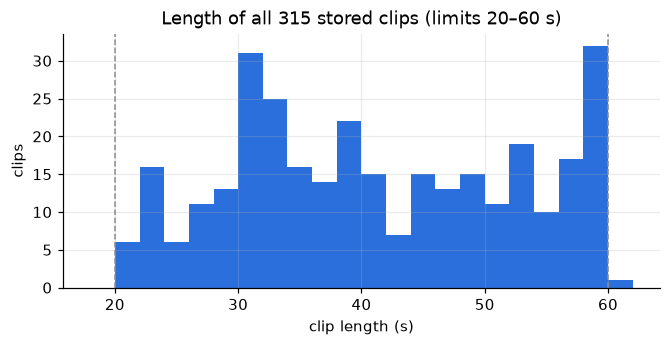

In [3]:
modes = Counter(s["mode"] for shots in clips.shots for s in shots)
shot_lengths = np.array([s["end"] - s["start"] for shots in clips.shots for s in shots])
print("framing mode per shot:", dict(modes))
print(f"shots per clip: median {np.median([len(s) for s in clips.shots]):.0f}; "
      f"shortest shot {shot_lengths.min():.2f} s (the minimum shot length is 0.5 s, decision 0013)")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clips.length_s, bins=np.arange(18, 63, 2), color=COLORS[0])
for x in (selection.MIN_S, selection.MAX_S):
    ax.axvline(x, color=GREY, ls="--", lw=1)
ax.set(xlabel="clip length (s)", ylabel="clips", title=f"Length of all {len(clips)} stored clips (limits 20–60 s)")
plt.show()

## 2. Replay on the relevance test episodes: teacher vs. live student

For each test episode we take the teacher curve (from `relevance_pseudo_labels`) and the live
student's curve, recomputed from its saved weights as in notebook 03. We run `select_spans` on
both with the episode's timed words from the database.

In [4]:
async def timed_words(upload_id):
    async with session_factory() as db:
        segs = (await db.execute(select(TranscriptSegment).where(TranscriptSegment.upload_id == upload_id)
                                 .order_by(TranscriptSegment.segment_index)
                                 .options(selectinload(TranscriptSegment.words)))).scalars().all()
    return words_from_segments(list(segs))


_, _, _, episodes, preds = await retrain._predictions(session_factory, "bilstm-e5s-20261114-i2", "test")
replay = []
for e in episodes:
    words = await timed_words(e.upload_id)
    teacher = e.target
    student = preds[e.upload_id][2]
    duration = e.windows[-1].end
    for name, curve in (("teacher", teacher), ("student", student)):
        wins = [ScoreWindow(i, w.start, w.end, float(s)) for i, (w, s) in enumerate(zip(e.windows, curve))]
        spans = select_spans(wins, words)
        peaks = find_peak_indices(smooth(list(curve)), e.windows[1].start - e.windows[0].start)
        ordered = sorted(spans, key=lambda s: s.start)
        gaps = [b.start - a.end for a, b in zip(ordered, ordered[1:])]  # silence between consecutive clips
        replay.append({
            "upload_id": e.upload_id, "curve": name, "clips": len(spans),
            "min_len": min(s.end - s.start for s in spans), "max_len": max(s.end - s.start for s in spans),
            "peaks": len(peaks), "curve_std": float(np.std(curve)),
            "min_gap_s": min(gaps) if gaps else np.nan,
            "in_first_or_last_30s": sum(s.start < 30 or s.end > duration - 30 for s in spans),
            "spans": spans,
        })
rp = pd.DataFrame(replay)
rp.drop(columns="spans").pivot_table(index="upload_id", columns="curve",
                                     values=["clips", "peaks", "curve_std", "min_gap_s", "in_first_or_last_30s"])

clips         curve_std         in_first_or_last_30s          \
curve     student teacher   student teacher              student teacher   
upload_id                                                                  
5             5.0     5.0     0.083   0.124                  0.0     0.0   
6             5.0     5.0     0.094   0.145                  0.0     0.0   
7             5.0     5.0     0.081   0.109                  0.0     0.0   
35            5.0     5.0     0.105   0.133                  0.0     0.0   
43            5.0     5.0     0.087   0.141                  0.0     0.0   
50            5.0     5.0     0.076   0.127                  0.0     1.0   
51            5.0     5.0     0.085   0.122                  0.0     0.0   
55            5.0     5.0     0.078   0.119                  0.0     0.0   

          min_gap_s           peaks          
curve       student teacher student teacher  
upload_id                                    
5             40.59   48.04    15.0    14.0  
6             39.79   19.19    14.0    16.0  
7            134.95   52.32    16.0    17.0  
35           205.16  163.44    27.0    22.0  
43           239.43  247.90    21.0    25.0  
50           118.35   50.40    27.0    27.0  
51            31.21   42.93    22.0    24.0  
55           103.10   73.58    23.0    22.0

In [5]:
st = rp[rp.curve == "student"]
print(f"student: {st.clips.sum()} clips over {len(st)} episodes; lengths {st.min_len.min():.1f}–{st.max_len.max():.1f} s; "
      f"{st.peaks.min()}–{st.peaks.max()} peaks per episode; curve std {st.curve_std.min():.3f}–{st.curve_std.max():.3f}; "
      f"min gap between clips {st.min_gap_s.min():.0f}–{st.min_gap_s.max():.0f} s; "
      f"clips in the first/last 30 s: {st.in_first_or_last_30s.sum()} (teacher: {rp[rp.curve == 'teacher'].in_first_or_last_30s.sum()})")


def count_near(rule):
    near = total = 0
    for _, g in rp.groupby("upload_id"):
        t_spans = g[g.curve == "teacher"].spans.iloc[0]
        for s in g[g.curve == "student"].spans.iloc[0]:
            total += 1
            near += any(rule(s, t) for t in t_spans)
    return near, total


mid = lambda s: (s.start + s.end) / 2  # noqa: E731
for name, rule in [("start times within 30 s", lambda s, t: abs(s.start - t.start) <= 30),
                   ("mid-points within 30 s", lambda s, t: abs(mid(s) - mid(t)) <= 30)]:
    n, total = count_near(rule)
    print(f"student clips with a teacher clip whose {name}: {n} of {total}")
print("report (decision 0024 §8): 22 of 40 'within 30 s of a p3 clip'; the matching rule was not recorded")

student: 40 clips over 8 episodes; lengths 20.5–59.6 s; 14–27 peaks per episode; curve std 0.076–0.105; min gap between clips 31–239 s; clips in the first/last 30 s: 0 (teacher: 1)
student clips with a teacher clip whose start times within 30 s: 21 of 40
student clips with a teacher clip whose mid-points within 30 s: 21 of 40
report (decision 0024 §8): 22 of 40 'within 30 s of a p3 clip'; the matching rule was not recorded


**Check against the record (decision 0024 §8, report *Relevance Model*).**
- Matching: five clips per episode, lengths within 20–60 s, 14–27 peaks after smoothing, and
  minimum gaps of 31–239 s.
- Student clips in the first or last 30 s: none, against one for the teacher.
- Two small differences:
  - Near-teacher clips: 21 of 40 here, against 22 recorded. The recorded matching rule is not
    known, and both rules above give 21.
  - Curve std: up to 0.105 here, against 0.110 recorded.

Neither difference changes the conclusion: the curves are not flat, and about half the clips are
the teacher's moments.

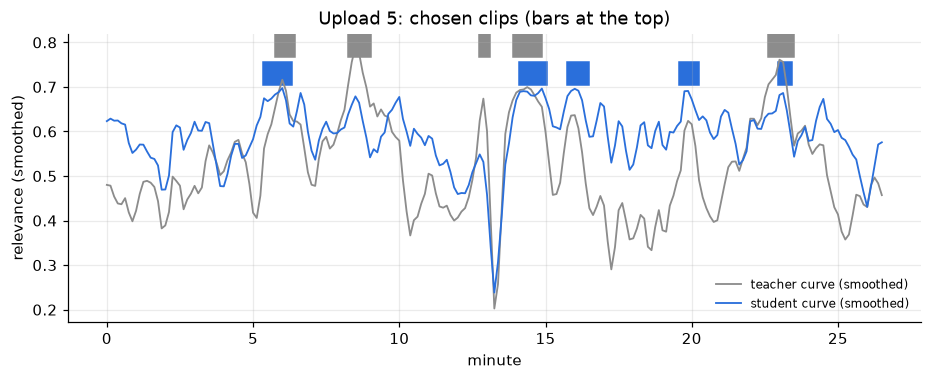

In [6]:
uid = 5
e = {x.upload_id: x for x in episodes}[uid]
fig, ax = plt.subplots(figsize=(10, 3.4))
t = np.array([w.start for w in e.windows]) / 60
for i, (name, curve) in enumerate((("teacher", e.target), ("student", preds[uid][2]))):
    ax.plot(t, smooth(list(curve)), color=[GREY, COLORS[0]][i], lw=1.2, label=f"{name} curve (smoothed)")
    for s in rp[(rp.upload_id == uid) & (rp.curve == name)].spans.iloc[0]:
        ax.axvspan(s.start / 60, s.end / 60, ymin=0.92 - 0.1 * i, ymax=1.0 - 0.1 * i, color=[GREY, COLORS[0]][i])
ax.set(xlabel="minute", ylabel="relevance (smoothed)", title=f"Upload {uid}: chosen clips (bars at the top)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.show()

## Summary

- Every stored clip respects the 20–60 s limits.
- The report's statement that every shot was framed in *crop* mode referred to the first episode.
  Over all stored clips, crop covers 99 % of the shots, and the rest fall back to *fit*
  (letterbox) when no usable face is found.
- The replay on the 8 test episodes reproduces the M15 regression check: the student yields five
  clips per episode, within the limits, from curves that are not flat. About half of its clips
  start near a teacher clip; the rest are different moments.
- Whether the clips are *good* was judged by eye: the rendered clips of uploads 5, 35 and 43 were
  approved (report, *Relevance Model*). That is the limitation: no audience data exists yet.